# Lab 3: Pretraining a GPT model

This lab is about pretraining large language models (LLMs). You will work through the full pretraining process for a GPT model, explore different settings, and implement optimisations that make training more efficient. You will also reflect on the impact of data curation on the quality of the pretrained model. By the end of the lab, you will have a solid understanding of how LLMs are trained from scratch.

*Tasks you can choose for the oral exam are marked with the graduation cap 🎓 emoji.*

In [1]:
import math
import os
import time
from dataclasses import dataclass

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from gpt2 import Config, Model

## Part 1: Pretraining pipeline

The GPT pretraining pipeline builds on the basic training loop for neural language models you have seen before, but includes several enhancements that improve stability and efficiency when training large models:

* It uses the [AdamW](https://pytorch.org/docs/stable/generated/torch.optim.AdamW.html) optimiser with weight decay instead of vanilla stochastic gradient descent.
* It implements a cosine decay learning rate schedule with a linear warmup phase.
* It accumulates gradient updates across multiple batches to allow training with larger effective batch sizes.
* It uses gradient clipping to prevent exploding gradients.

### Training configuration

We begin by setting up a configuration object that defines the key parameters of the training process.

The original 124M-parameter GPT-2 model released by OpenAI (and featured in lab&nbsp;2) was trained on WebText, a private dataset with approximately 10B tokens of Internet data. (There is no reliable public source that reports the exact number.) We will refer to this model as **Model&nbsp;A**.

The training pipeline in this lab is configured to train a Chinchilla-optimal model with the same architecture as Model&nbsp;A but using the publicly released [FineWeb-Edu](https://huggingface.co/datasets/HuggingFaceFW/fineweb-edu) dataset. We will refer to this model as **Model&nbsp;B**.

In [2]:
@dataclass
class TrainingConfig:
    device: torch.device = torch.device(
            "mps" if torch.backends.mps.is_available() else "cpu"
        )
    shard_dir: str = "data"

    # Training steps and data processing
    n_steps: int = 4768
    n_tokens_per_step: int = 524288
    batch_size: int = 64
    sequence_len: int = 1024
    n_vocab: int = 50304

    # Optimisation and learning rate scheduling
    weight_decay: float = 0.1
    max_lr: float = 6e-4
    min_lr: float = 6e-5
    n_warmup_steps: int = 715
    n_decay_steps: int = 4053
    betas: tuple[float, float] = (0.9, 0.95)
    clip_norm: float = 1.0

#### 🎓 Task 3.01: Explaining the training parameters

Your first task is to explain the purpose of the training parameters. Some of them will already be known to you from the lectures, while others will become clear first as you progress through the lab and see how everything fits together. Because of this, it is best to revisit and complete this task towards the end of the lab when you have a full understanding of the training process.

One parameter to note is the vocabulary size. GPT-2 uses 50,257 tokens, but for training on a GPU, it is helpful to have numbers that are more hardware-friendly. Specifically, numbers with many factors of&nbsp;2 can lead to more efficient computation. To achieve this, we set the vocabulary size to 50,304, which is slightly larger than needed but has many factors of&nbsp;2. Note that the extra tokens will not be used in practice — they simply act as placeholders without meaningful embeddings.

#### ANSWER - Task 3.01 (Was done last)

The training configuration controls how much data is processed, how the model is optimised, and how the learning rate changes during training.

- `device` specifies where the model and tensors are stored and where computations are performed. In this notebook I use Apple MPS when available, otherwise CPU.

- `shard_dir` specifies the directory containing the tokenised FineWeb-Edu training shards.

- `n_steps = 4768` is the total number of optimisation steps. Since every step processes a fixed number of tokens, this also determines the total amount of training data seen by the model.

- `n_tokens_per_step = 524288` is the effective number of tokens used for each optimisation step. If the physical batch is too small to contain this many tokens at once, gradient accumulation is used across several micro-batches.

- `batch_size = 64` is the number of sequences processed simultaneously in one micro-batch. A smaller value reduces memory usage, while a larger value can improve hardware utilisation.

- `sequence_len = 1024` is the number of tokens in each training sequence. This matches the maximum context length of the GPT-2 architecture.

- `n_vocab = 50304` is the vocabulary size used by the model. GPT-2 actually uses 50,257 tokens, but the vocabulary is padded to 50,304 because this value is more hardware-friendly. The additional token IDs are unused placeholders.

- `weight_decay = 0.1` controls the strength of weight decay in AdamW. Weight decay regularises the model by discouraging excessively large parameter values.

- `max_lr = 6e-4` is the maximum learning rate reached after the warmup phase.

- `min_lr = 6e-5` is the minimum learning rate reached after cosine decay.

- `n_warmup_steps = 715` is the number of initial optimisation steps during which the learning rate increases linearly from a small value to `max_lr`. Warmup helps make the beginning of training more stable.

- `n_decay_steps = 4053` is the number of steps during which the learning rate follows the cosine decay schedule from `max_lr` towards `min_lr`.

- `betas = (0.9, 0.95)` are the AdamW momentum parameters. $\beta_1$ controls the moving average of the gradients, while $\beta_2$ controls the moving average of the squared gradients.

- `clip_norm = 1.0` is the maximum allowed gradient norm. If the gradient norm becomes larger than this value, the gradients are scaled down before the optimiser update. This helps prevent unstable updates caused by exploding gradients.

With the default configuration, the total amount of training data processed is approximately

$$
4768 \times 524288 \approx 2.5 \text{ billion tokens},
$$

which corresponds to the intended Chinchilla-optimal training budget for Model B.

### Model

Next, we set up the model. Our goal is to match the original training setup of GPT-2 as closely as possible. To do this, we follow the initialisation strategy outlined in the key research papers about GPT ([Radford et al., 2018](https://cdn.openai.com/research-covers/language-unsupervised/language_understanding_paper.pdf); [Radford et al., 2019](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf); [Brown et al., 2020](https://arxiv.org/pdf/2005.14165)) as well as the official implementation ([link](https://github.com/openai/gpt-2)). Here is a summary of this strategy:

* Token embeddings → Normal distribution with mean $0$ and standard deviation $0.02$.
* Position embeddings → Normal distribution with mean $0$ and standard deviation $0.01$.
* Weights of the linear layers → Normal distribution with mean $0$ and standard deviation $0.02$.
* Biases of the linear layers → Initialised to zeros.
* Weight sharing between the final linear layer and the token embedding.

#### 🧩 Task 3.02: Initialising the model

Expand the skeleton code below to create a fresh model and initialise it according to the GPT-2 strategy.

In [3]:
def configure_model(config: TrainingConfig) -> Model:
    # Create a fresh GPT model with the configured vocabulary size
    model = Model(Config(n_vocab=config.n_vocab))

    # Initialise token embeddings:
    # GPT-2 uses a normal distribution with mean 0 and std 0.02
    nn.init.normal_(model.wte.weight, mean=0.0, std=0.02)

    # Initialise positional embeddings:
    # GPT-2 uses a smaller standard deviation of 0.01
    nn.init.normal_(model.wpe.weight, mean=0.0, std=0.01)

    # Initialise all linear layers
    for module in model.modules():
        if isinstance(module, nn.Linear):
            # Linear-layer weights are sampled from N(0, 0.02^2)
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

            # Linear-layer biases are initialised to zero
            if module.bias is not None:
                nn.init.zeros_(module.bias)

    # Share the weights of the output language-model head
    # with the token embedding matrix.
    model.lm_head.weight = model.wte.weight

    return model

#### Scaled residual initialisation

There is one important detail in the GPT-2 initialisation strategy that we have not addressed yet. [Radford et al. (2019)](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf) write (Section&nbsp;2.3):

> A modified initialization which accounts for the accumulation on the residual path with model depth is used. We scale the weights of residual layers at initialization by a factor of $1/\sqrt{N}$ where $N$ is the number of residual layers.

Why is this necessary? One of the challenges in training large language models is controlling the variance of activations. However, there are two points in the GPT architecture where variance can grow uncontrollably: the residual connections after the multi-head attention and the MLP. Since these connections simply add activations from previous layers, their variances increase with depth. To see this, note that if we sum $N$ independent normally distributed variables with variance $\sigma^2$, the result has variance $N \sigma^2$.

#### 🎓 Task 3.03: Implementing the scaled residual initialisation

**Step&nbsp;1.** Suppose each summand in a sum of $N$ independent normally distributed variables with variance $\sigma^2$ is scaled by a factor of&nbsp;$k$. The total variance then becomes $N k^2 \sigma^2$. What happens to the total variance if we choose $k = 1/\sqrt{N}$, as in GPT-2?

**Step&nbsp;2.** Test the mathematical theory with a simulation. Generate normally distributed activations using `torch.randn()`. Sum the activations across $N$ hypothetical residual layers, first without scaling and then with the $1/\sqrt{N}$ adjustment. Compare the two cases by producing a plot showing the variance at each layer. To compute the variance of a tensor, use `torch.var()`.

**Step&nbsp;3.** Update your model initialisation from the previous task to include the scaled residual initialisation. The adjustment should only be applied to the linear layer at the end of the multi-head attention and MLP blocks (`c_proj`). Note that a GPT model with $L$&nbsp;layers has $N = 2 L$ residual layers, because there are two residual connections in each layer (after the multi-head attention and the MLP).

#### ANSWER - Step 1

Without scaling, the variance of the sum of $N$ independent variables, each with variance $\sigma^2$, is

$$
N\sigma^2.
$$

If each variable is scaled by

$$
k = \frac{1}{\sqrt{N}},
$$

then the total variance becomes

$$
Nk^2\sigma^2
=
N\left(\frac{1}{\sqrt{N}}\right)^2\sigma^2
=
N\frac{1}{N}\sigma^2
=
\sigma^2.
$$

Therefore, scaling each residual contribution by $1/\sqrt{N}$ prevents the variance from growing proportionally with the number of residual layers. Instead, the total variance after all residual additions remains approximately equal to the variance of a single unscaled contribution.

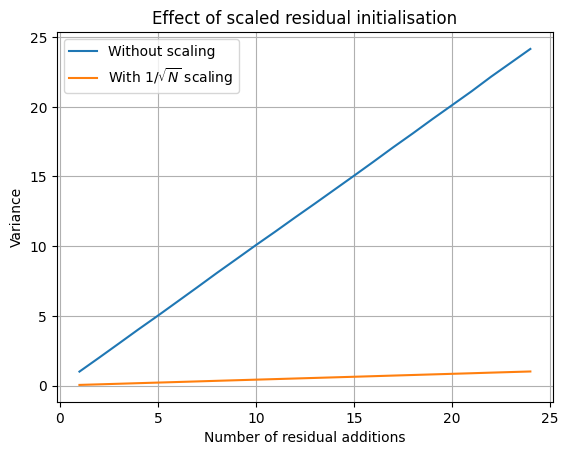

In [4]:
## STEP 2


import matplotlib.pyplot as plt

# GPT-2 has 12 Transformer blocks and two residual connections per block,
# so there are N = 2 * 12 = 24 residual additions.
N = 24

# Use many samples so that the measured variance is close to
# the theoretical variance.
n_samples = 100_000

# Generate one independent normally distributed contribution
# for every hypothetical residual layer.
activations = torch.randn(N, n_samples)

# ----- Without scaled residual initialisation -----

# Sum the residual contributions progressively.
unscaled_sum = torch.zeros(n_samples)
unscaled_variances = []

for i in range(N):
    unscaled_sum += activations[i]
    unscaled_variances.append(torch.var(unscaled_sum).item())


# ----- With 1/sqrt(N) scaling -----

scale = 1 / math.sqrt(N)

scaled_sum = torch.zeros(n_samples)
scaled_variances = []

for i in range(N):
    scaled_sum += scale * activations[i]
    scaled_variances.append(torch.var(scaled_sum).item())


# Plot the variance after every residual addition.
layers = range(1, N + 1)

plt.plot(layers, unscaled_variances, label="Without scaling")
plt.plot(layers, scaled_variances, label=r"With $1/\sqrt{N}$ scaling")

plt.xlabel("Number of residual additions")
plt.ylabel("Variance")
plt.title("Effect of scaled residual initialisation")
plt.legend()
plt.grid()
plt.show()

#### ANSWER - Step 2

The simulation confirms the theoretical result. Without scaling, the variance grows approximately linearly with the number of residual additions and reaches approximately $N$.

With $1/\sqrt{N}$ scaling, the variance grows much more slowly and reaches approximately $1$ after all $N$ residual additions.

This prevents the scale of the activations from increasing excessively with model depth.

In [5]:
### Step 3 - Update configure model

def configure_model(config: TrainingConfig) -> Model:
    # Create the GPT-2 model configuration and a fresh model.
    model_config = Config(n_vocab=config.n_vocab)
    model = Model(model_config)

    # Initialise token embeddings with std = 0.02.
    nn.init.normal_(model.wte.weight, mean=0.0, std=0.02)

    # Initialise positional embeddings with std = 0.01.
    nn.init.normal_(model.wpe.weight, mean=0.0, std=0.01)

    # GPT-2 has two residual connections per Transformer block:
    # one after attention and one after the MLP.
    n_residual_layers = 2 * model_config.n_layer

    # Initialise all linear layers.
    for name, module in model.named_modules():
        if isinstance(module, nn.Linear):
            std = 0.02

            # The c_proj layers feed directly into residual connections.
            # Scale their initialisation by 1/sqrt(N), where N = 2L.
            if name.endswith("c_proj"):
                std /= math.sqrt(n_residual_layers)

            nn.init.normal_(module.weight, mean=0.0, std=std)

            # All linear biases are initialised to zero.
            if module.bias is not None:
                nn.init.zeros_(module.bias)

    # Share the output-layer weights with the token embeddings.
    model.lm_head.weight = model.wte.weight

    return model

#### ANSWER - Step 3

The model initialisation from Task 3.02 was updated to include the scaled residual initialisation used by GPT-2.

The main change is that the model now checks the names of the linear layers using `model.named_modules()`. This allows the `c_proj` layers at the end of the attention and MLP blocks to be identified.

For these layers, the standard deviation of the weight initialisation is changed from

$$
0.02
$$

to

$$
\frac{0.02}{\sqrt{2L}},
$$

where $L$ is the number of Transformer layers. Since GPT-2 has two residual connections per Transformer block, the total number of residual layers is $N = 2L$.

All other linear layers are still initialised with standard deviation $0.02$, while biases remain zero and the output layer continues to share its weights with the token embedding layer.

This scaling reduces the contribution of each residual branch at initialisation and helps prevent the variance of activations from growing excessively as the model becomes deeper.

### Data

As mentioned before, the original Model&nbsp;A was pretrained on a 10B-token non-public dataset collected by OpenAI. The pretraining data for our Model&nbsp;B comes from the public [FineWeb-Edu](https://huggingface.co/datasets/HuggingFaceFW/fineweb-edu) dataset. The full dataset contains 1.3&nbsp;trillion tokens, much more than what we need to train a Chinchilla-optimal model. (How much is that?)

In this lab, we will mostly work with a tiny sample of the full pretraining data for Model&nbsp;B. We use a preprocessed version of the data that has been tokenised with the GPT-2 tokeniser and chopped into smaller chunks called **shards**. The function below loads these shards from a given directory and yields them as PyTorch tensors.

In [6]:
def shards(shard_dir: str):
    for shard in sorted(os.listdir(shard_dir)):
        yield torch.from_numpy(np.load(os.path.join(shard_dir, shard)).astype(np.int64))

In total, our training data consists of 300M tokens:

In [7]:
sum(s.numel() for s in shards(TrainingConfig().shard_dir))

300000000

#### 🎓 Task 3.04: Batching the data

Implement a function `make_batches()` that packages the token indices in the shards into pairs of input and output batches suitable for language modelling training. One efficient way to do this is sketched in the cell below:

In [8]:
shard = torch.tensor(range(15), dtype=torch.long)

# Suppose we want to package the tokens in this shard into batches of shape (2, 3).

# Step 1: Segment the shard into overlapping chunks of size 2 * 3 + 1
chunk1 = shard[0:7]
chunk2 = shard[6:13]
excess = shard[12:]

# Step 2: Create batches from all but the last and all but the first token in each chunk
x1, y1 = chunk1[:-1].view(2, 3), chunk1[1:].view(2, 3)
x2, y2 = chunk2[:-1].view(2, 3), chunk2[1:].view(2, 3)

The following code cell shows the signature of `make_batches()`.

In [9]:
def make_batches(config: TrainingConfig):
    # Number of tokens contained in one input batch.
    # For the default configuration:
    # 64 * 1024 = 65,536 tokens.
    batch_tokens = config.batch_size * config.sequence_len

    # Stores tokens that were left over from the previous shard.
    # These tokens are carried into the next shard so that batches
    # are allowed to stretch across shard boundaries.
    buffer = torch.empty(0, dtype=torch.long)

    for shard in shards(config.shard_dir):
        # Prepend any unused tokens from the previous shard.
        if buffer.numel() > 0:
            shard = torch.cat((buffer, shard))

        # We need batch_tokens + 1 tokens because the target sequence
        # is the input sequence shifted one position to the right.
        position = 0

        while position + batch_tokens + 1 <= shard.numel():
            # Extract enough tokens to construct both x and y.
            chunk = shard[position : position + batch_tokens + 1]

            # x contains every token except the last.
            # y contains every token except the first.
            #
            # Therefore y is exactly x shifted one token to the right.
            x = chunk[:-1].view(config.batch_size, config.sequence_len)
            y = chunk[1:].view(config.batch_size, config.sequence_len)

            yield x, y

            # Move forward by batch_tokens rather than batch_tokens + 1.
            # The final token of this chunk is therefore reused as the
            # first token needed for the next next-token prediction.
            position += batch_tokens

        # Keep all remaining tokens and prepend them to the next shard.
        buffer = shard[position:]

In [10]:
config = TrainingConfig()

batches = make_batches(config)

# Inspect the first batch.
x, y = next(batches)

print("x shape:", x.shape)
print("y shape:", y.shape)

# Verify that the targets are shifted by one token.
print("Last few x tokens:", x.flatten()[:10])
print("Corresponding y tokens:", y.flatten()[:10])

x shape: torch.Size([64, 1024])
y shape: torch.Size([64, 1024])
Last few x tokens: tensor([ 2982,    11,  2026,  1510, 10860,   286,  9260,   547, 16318,  1497])
Corresponding y tokens: tensor([   11,  2026,  1510, 10860,   286,  9260,   547, 16318,  1497,    11])


In [11]:
n_batches = sum(1 for _ in make_batches(config))
print("Number of batches:", n_batches)

Number of batches: 4577


#### REMARK - Task 3.04

The `make_batches()` function constructs input-target pairs for next-token prediction. For each batch containing $B \times T$ input tokens, it reads $B \times T + 1$ consecutive tokens. The first $B \times T$ tokens form the input $x$, while the final $B \times T$ tokens form the target $y$. Therefore, $y$ is simply $x$ shifted one token to the right.

Any tokens remaining at the end of a shard are carried over and combined with the next shard. This allows batches to span shard boundaries instead of unnecessarily discarding data. Only the remaining tokens at the end of the final shard that are insufficient to form a complete batch are dropped.

With the default batch size of $64$ and sequence length of $1024$, each input and target batch has shape $(64, 1024)$, and the provided training data produces 4577 complete batches.

**Hints and considerations:**

* Batches can stretch across shards. You will have to carry over excess tokens at the end of shards to the next batch.
* All batches should have the same shape. Drop excess tokens at the end of the last shard.
* The correct number of batches of shape $(64, 1024)$ for the training shards is $4577$.

### Optimiser

The code in the cell below configures the [AdamW](https://pytorch.org/docs/stable/generated/torch.optim.AdamW.html) optimiser. It uses weight decay on all parameters with two or more dimensions (e.g., weights in linear layers), and no decay on the remaining parameters. If the model is on a CUDA device, the code uses the “fused” implementation of the optimiser for efficiency.

In [12]:
def configure_optimizer(model: Model, config: TrainingConfig):
    params = [p for p in model.parameters() if p.requires_grad]
    decay_params = [p for p in params if p.dim() >= 2]
    no_decay_params = [p for p in params if p.dim() < 2]
    param_groups = [
        {"params": decay_params, "weight_decay": config.weight_decay},
        {"params": no_decay_params, "weight_decay": 0.0},
    ]
    return torch.optim.AdamW(
        param_groups,
        lr=config.max_lr,
        betas=config.betas,
        fused=(config.device.type == "cuda"),
    )

#### 🎓 Task 3.05: Exploring the beta parameters

The AdamW optimiser is controlled by two hyperparameters $\beta_1$ and $\beta_2$:

* $\beta_1$ controls the moving average of past gradients.
* $\beta_2$ controls the moving average of past squared gradients, which affects the adaptive learning rate scaling.

Lower values correspond to reduced effect of the respective average, that is, less smoothing and faster adaptation to recent values. In this task, you will explore how different beta values affect the convergence behaviour of the optimiser.

The code below applies the optimiser to the function $f(x) = (x-2)^2 + (y+3)^2$, which has a global minimum at $(2, -3)$. The code yields the trajectories of the parameter values $(x, y)$ visited by Adam when started at $(-4, 5)$ for different values of&nbsp;$\beta_1$ and $\beta_2$.

In [13]:
def adam_trajectories(betas):
    def loss_function(x, y):
        return (x - 2) ** 2 + (y + 3) ** 2

    for beta1, beta2 in betas:
        x = torch.tensor([-4.0], requires_grad=True)
        y = torch.tensor([5.0], requires_grad=True)
        optimizer = torch.optim.AdamW((x, y), lr=0.125, betas=(beta1, beta2))
        trajectory = []
        for _ in range(100):
            optimizer.zero_grad()
            loss = loss_function(x, y)
            loss.backward()
            optimizer.step()
            trajectory.append((x.item(), y.item()))
        yield trajectory, f"β₁ = {beta1}, β₂ = {beta2}"

 Your task is to visualise different trajectories in a plot and analyse the results. Proceed as follows:

* Start by plotting the trajectory for the default values for $\beta_1$ and $\beta_2$. (Consult the PyTorch documentation to find these.)
* Add the plot for the beta values used in our training configuration. For this simple example, do you see a significant difference?
* Add more plots to see what happens if the beta values are too high or too low.

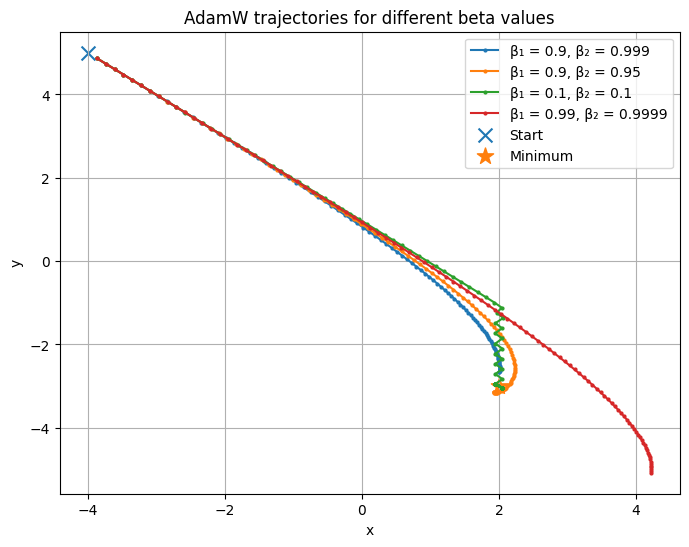

In [14]:
import matplotlib.pyplot as plt

# Beta values to compare:
# - PyTorch default
# - Values used in our GPT training configuration
# - Very low values: little smoothing
# - Very high values: strong smoothing
betas = [
    (0.9, 0.999),   # PyTorch default
    (0.9, 0.95),    # GPT training configuration
    (0.1, 0.1),     # Very low beta values
    (0.99, 0.9999), # Very high beta values
]

plt.figure(figsize=(8, 6))

for trajectory, label in adam_trajectories(betas):
    trajectory = np.array(trajectory)

    # Plot the sequence of parameter values visited by AdamW.
    plt.plot(
        trajectory[:, 0],
        trajectory[:, 1],
        marker="o",
        markersize=2,
        label=label,
    )

# Starting point and global minimum.
plt.scatter(-4, 5, marker="x", s=100, label="Start")
plt.scatter(2, -3, marker="*", s=150, label="Minimum")

plt.xlabel("x")
plt.ylabel("y")
plt.title("AdamW trajectories for different beta values")
plt.legend()
plt.grid()
plt.show()

#### ANSWER - Task 3.05

The default AdamW parameters in PyTorch are $\beta_1 = 0.9$ and $\beta_2 = 0.999$, while the training configuration used in this lab sets $\beta_1 = 0.9$ and $\beta_2 = 0.95$.

In the plot, these two configurations follow very similar trajectories towards the minimum at $(2,-3)$. The configuration used in the lab shows only a small difference from the PyTorch default, so for this simple optimisation problem changing $\beta_2$ from $0.999$ to $0.95$ does not have a significant effect on convergence.

More extreme beta values lead to clearer differences. With very low values, $\beta_1 = 0.1$ and $\beta_2 = 0.1$, the optimiser reacts much more strongly to recent gradients and shows noticeable oscillations near the minimum because there is very little smoothing.

With very high values, $\beta_1 = 0.99$ and $\beta_2 = 0.9999$, the optimiser retains information from previous gradients for much longer. In this experiment, this causes a large overshoot past the minimum and the parameters have not converged within the 100 optimisation steps.

Overall, the experiment shows that moderate beta values provide a useful balance between smoothing and adaptation, while values that are too low can cause oscillatory behaviour and values that are too high can make the optimiser react too slowly and overshoot the optimum.

### Learning rate scheduling

Your next task is to implement the learning rate scheduler. As mentioned before, GPT-2 is trained with cosine decay from a maximum to a minimum learning rate in conjunction with a linear warmup phase.

#### 🎓 Task 3.06: Implementing cosine decay

Implement a function `get_lr_factor()` that determines the learning for a given `step`. To work with the rest of the implementation, this function should return its result as a factor of the maximum learning rate. In particular, the result at the end of the linear warmup should be&nbsp;$1$. Validate your implementation by plotting the function against the training steps.

In [15]:
def get_lr_factor(step: int, config: TrainingConfig) -> float:
    # Phase 1: linear warmup from 0 to max_lr
    if step < config.n_warmup_steps:
        return (step + 1) / config.n_warmup_steps

    # Phase 2: cosine decay from max_lr to min_lr
    if step < config.n_warmup_steps + config.n_decay_steps:
        decay_step = step - config.n_warmup_steps

        # Progress through the decay phase, from 0 to 1
        progress = decay_step / config.n_decay_steps

        # Cosine factor decreases smoothly from 1 to 0
        cosine = 0.5 * (1 + math.cos(math.pi * progress))

        # Minimum learning rate expressed as a fraction of max_lr
        min_factor = config.min_lr / config.max_lr

        # Interpolate between 1 and min_factor
        return min_factor + (1 - min_factor) * cosine

    # Phase 3: keep the learning rate at min_lr
    return config.min_lr / config.max_lr

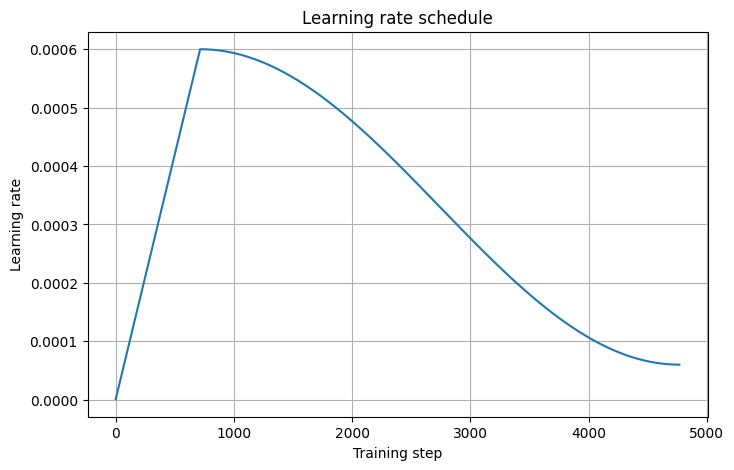

In [16]:
## SIMPLE VALIDATION PLOT

config = TrainingConfig()

steps = range(config.n_steps)
lr_factors = [get_lr_factor(step, config) for step in steps]

learning_rates = [
    factor * config.max_lr
    for factor in lr_factors
]

plt.figure(figsize=(8, 5))

plt.plot(steps, learning_rates)

plt.xlabel("Training step")
plt.ylabel("Learning rate")
plt.title("Learning rate schedule")
plt.grid()

plt.show()

#### ANSWER - Task 3.06

The learning-rate schedule consists of two main phases.

During the first 715 steps, the learning rate increases linearly until it reaches the maximum learning rate of $6 \times 10^{-4}$. This warmup phase helps stabilise training at the beginning.

After warmup, the learning rate follows a cosine decay schedule and gradually decreases towards the minimum learning rate of $6 \times 10^{-5}$.

The validation plot shows the expected linear warmup followed by a smooth cosine-shaped decay.

**Hint:** For $x \in [0, 1]$, the relevant cosine decay is described by the term $\frac{1}{2} \cdot (1 + \text{cos}(\pi x))$.

### Training loop

At this point, we have everything in place to put together a first version of the training loop. Here it is:

In [17]:
def train(config: TrainingConfig):
    model = configure_model(config)
    model = model.to(config.device)
    batches = make_batches(config)
    optimizer = configure_optimizer(model, config)
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lambda lr: get_lr_factor(lr, config),
    )
    n_micro_steps = config.n_tokens_per_step // (
        config.batch_size * config.sequence_len
    )
    for step in range(config.n_steps):
        model.train()
        optimizer.zero_grad()
        running_loss = 0.0
        for micro_step in range(n_micro_steps):
            x, y = next(batches)
            x, y = x.to(config.device), y.to(config.device)
            logits = model(x)
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), y.view(-1))
            loss.backward()
            running_loss += loss.item()
        nn.utils.clip_grad_norm_(model.parameters(), config.clip_norm)
        optimizer.step()
        lr = scheduler.get_last_lr()[0]
        scheduler.step()
        print(f"step {step:4d} | loss: {running_loss:.4f} | lr: {lr:.4e}")

Most of the steps should look familiar from previous labs or earlier tasks in this notebook. However, a few key aspects will be new:

**Moving the model and data to the training device.** The model and each batch are moved to the training device using `.to()`. In our training configuration, `config.device` is an NVIDIA GPU, which supports fast tensor computations.

**Gradient accumulation.** Instead of taking an optimisation step after every batch, we accumulate gradients over multiple batches (“micro-steps”). Each batch contributes to the gradients using `loss.backward()`.

**Gradient clipping.** Before updating weights, the gradients are clipped using `clip_grad_norm_()`. This prevents excessively large updates that could destabilise training. The clipping threshold is set by `config.clip_norm`.

#### 🧩 Task 3.07: Running the training loop

Try to train a model by executing the code below:

In [18]:
train(TrainingConfig(batch_size=16, n_steps=5))

step    0 | loss: 351.1811 | lr: 8.3916e-07
step    1 | loss: 349.6134 | lr: 1.6783e-06
step    2 | loss: 346.5094 | lr: 2.5175e-06
step    3 | loss: 342.0928 | lr: 3.3566e-06
step    4 | loss: 337.1960 | lr: 4.1958e-06


#### ANSWER - Task 3.07

On my machine, the original batch size of 64 exceeded the available GPU memory, so I reduced the batch size. A batch size of 16 fits successfully on the Apple MPS device. I ran the training loop for 5 optimisation steps, which was sufficient to inspect the initial training behaviour.

The initial reported loss was approximately 350. For a randomly initialised language model with vocabulary size $V = 50304$, the model should initially assign approximately equal probability to every token. Therefore, the expected cross-entropy loss for one batch is

$$
-\log\left(\frac{1}{V}\right)
=
\log(V)
=
\log(50304)
\approx 10.83.
$$

With a batch size of 16, each optimisation step consists of

$$
\frac{524288}{16 \times 1024} = 32
$$

micro-steps.

The current implementation sums the loss over all 32 micro-steps, so the expected reported loss is approximately

$$
32 \times 10.83 \approx 346.6,
$$

which closely matches the observed initial losses of around 350.

This indicates that the high reported loss is caused by the current gradient accumulation implementation. The losses, and more importantly the gradients, are being summed across micro-batches instead of being averaged. This will be corrected in Task 3.08.

You will run into two problems:

**Memory issues.** The training configuration for our Model&nbsp;B has been set up for an A100 GPU with 80GB of memory. If you are using a less powerful GPU, you will see an out-of-memory error. To fix this, reduce the batch size to lower the memory load on the GPU. Start with a value of&nbsp;4. Then, try doubling this value until you find the largest batch size that fits on your GPU. Note that you may have to restart the Jupyter kernel to reset the GPU after each adjustment.

**High losses.** The training losses start at very high values. Recall that the model’s goal is to predict the next token. At the start, the model’s weights are random, so we expect it to output a uniform distribution over the vocabulary. This means each token should have a probability of $1/V$, where $V$ is the vocabulary size. Given this, what should the initial loss be? Think about the cross-entropy loss for a uniform distribution.

(You will fix the problem with the high losses in the next task.)

#### 🎓 Task 3.08: Fixing the gradient accumulation

The gradient accumulation in the `train()` function is not implemented correctly. To see this, consider the following example. We set up a linear layer and pass in some random input of shape $[2, 3]$. First, we compute the loss and gradients in the normal way. Then, we do the same thing using gradient accumulation over two singleton batches, in the way this is implemented in `train()`. As you will see, the two outputs are different.

Your task is to fix the flawed implementation of gradient accumulation in the training loop.

1. Propose a fix for the problem illustrated in the example.
2. Validate your proposal by modifying the example.
3. Once you are convinced that your fix is correct, apply it to the training loop.
4. How does the fix affect the loss?

In [22]:
def accumulation_example():
    # Set up a simple model and simulate some input
    model = nn.Linear(3, 2)
    x = torch.randn(2, 3)
    y = torch.randint(0, 2, (2,))

    # --------------------------------------------------
    # Gradient computed using the complete batch
    # --------------------------------------------------
    model.zero_grad()

    output = model(x)
    loss = F.cross_entropy(output, y)
    loss.backward()

    full_batch_grad = model.weight.grad.clone()

    print("Gradient using complete batch:")
    print(full_batch_grad)


    # --------------------------------------------------
    # Gradient computed using gradient accumulation
    # --------------------------------------------------
    model.zero_grad()

    n_micro_steps = 2

    for i in range(n_micro_steps):
        output = model(x[i : i + 1])

        loss = F.cross_entropy(
            output,
            y[i : i + 1]
        )

        # Divide the loss by the number of micro-steps
        # so that the accumulated gradients are averaged.
        loss = loss / n_micro_steps

        loss.backward()

    accumulated_grad = model.weight.grad.clone()

    print("\nGradient using corrected accumulation:")
    print(accumulated_grad)

    print(
        "\nGradients match:",
        torch.allclose(
            full_batch_grad,
            accumulated_grad,
            atol=1e-6
        )
    )


accumulation_example()

Gradient using complete batch:
tensor([[ 0.8898, -0.8558, -0.0748],
        [-0.8898,  0.8558,  0.0748]])

Gradient using corrected accumulation:
tensor([[ 0.8898, -0.8558, -0.0748],
        [-0.8898,  0.8558,  0.0748]])

Gradients match: True


#### ANSWER - Steps 1 and 2

The original gradient accumulation implementation sums the gradients from all micro-batches. This makes the resulting gradient larger by approximately the number of micro-steps compared with computing the loss over the complete batch.

To correct this, the loss of each micro-batch is divided by the number of micro-steps before calling `backward()`:

```python
loss = loss / n_micro_steps
loss.backward()
```

Since differentiation is linear, accumulating these scaled gradients gives

$$
\frac{1}{M}
\sum_{i=1}^{M}
\nabla L_i,
$$

where $M$ is the number of micro-steps. This is equivalent to computing the gradient of the average loss over the complete effective batch.

After applying this correction to the provided example, the gradient obtained using micro-batches matches the gradient obtained from processing the complete batch directly.

In [23]:
def train(config: TrainingConfig):
    model = configure_model(config)
    model = model.to(config.device)

    batches = make_batches(config)

    optimizer = configure_optimizer(model, config)

    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lambda step: get_lr_factor(step, config),
    )

    n_micro_steps = config.n_tokens_per_step // (
        config.batch_size * config.sequence_len
    )

    for step in range(config.n_steps):
        model.train()
        optimizer.zero_grad()

        running_loss = 0.0

        for micro_step in range(n_micro_steps):
            x, y = next(batches)
            x, y = x.to(config.device), y.to(config.device)

            logits = model(x)

            loss = F.cross_entropy(
                logits.view(-1, logits.size(-1)),
                y.view(-1)
            )

            # Keep the unscaled loss for reporting
            running_loss += loss.item()

            # Scale the loss before backpropagation
            loss = loss / n_micro_steps

            loss.backward()

        # Average the reported loss across all micro-steps
        running_loss /= n_micro_steps

        nn.utils.clip_grad_norm_(
            model.parameters(),
            config.clip_norm
        )

        optimizer.step()

        lr = scheduler.get_last_lr()[0]
        scheduler.step()

        print(
            f"step {step:4d} | "
            f"loss: {running_loss:.4f} | "
            f"lr: {lr:.4e}"
        )

In [24]:
train(TrainingConfig(batch_size=16, n_steps=5))

step    0 | loss: 10.9526 | lr: 8.3916e-07
step    1 | loss: 10.9037 | lr: 1.6783e-06
step    2 | loss: 10.8021 | lr: 2.5175e-06
step    3 | loss: 10.6593 | lr: 3.3566e-06
step    4 | loss: 10.5067 | lr: 4.1958e-06


#### ANSWER - Steps 3 and 4

The same correction was applied to the full training loop. Each micro-batch loss is divided by the number of micro-steps before calling `backward()`, so the accumulated gradients correspond to the gradient of the average loss over the effective batch.

The unscaled losses are still accumulated for reporting, and the final `running_loss` is divided by the number of micro-steps before printing.

Before the correction, the reported initial loss was around 350 because the losses from 32 micro-steps were being summed. After the correction, the initial loss is approximately 10.95 and then decreases to about 10.51 after five optimisation steps.

This is consistent with the theoretical initial cross-entropy for a randomly initialised model with vocabulary size $V = 50304$:

$$
\log(50304) \approx 10.83.
$$

The corrected implementation therefore produces both properly scaled gradients and a meaningful average training loss.

## Part 2: Efficiency optimisations

Training LLMs from scratch is a computationally intensive task. Efficient training not only speeds up model convergence but also reduces hardware costs and energy consumption. As models grow in size, optimising the training process becomes increasingly important to ensure that resources are used effectively. In the second part of this lab, we will look into a few such optimisation techniques.

#### 🎓 Task 3.09: Profiling the training loop

Before we explore optimisations, we first need a way to measure training speed. We will define training speed as the **number of tokens processed per second**. Your task is to implement this measurement in the training loop.

**Step&nbsp;1.** Keep track of the number of tokens processed in each optimisation step.

**Step&nbsp;2.** Add a timer to measure the time taken per step. For accurate results, call `torch.cuda.synchronize()` before stopping the timer. This ensures all GPU computations finish before recording the time.

Once you have added this measurement, train the model for a few steps and answer the following questions:

* Based on your measured training speed, how long would it take to train on the toy data for this lab (300M tokens)?
* How much data and time would be required to train the full, Chinchilla-optimal Model&nbsp;B on your computer?

In [25]:
def train(config: TrainingConfig):
    model = configure_model(config)
    model = model.to(config.device)

    batches = make_batches(config)

    optimizer = configure_optimizer(model, config)

    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lambda step: get_lr_factor(step, config),
    )

    n_micro_steps = config.n_tokens_per_step // (
        config.batch_size * config.sequence_len
    )

    for step in range(config.n_steps):
        model.train()
        optimizer.zero_grad()

        running_loss = 0.0

        # Start timing this optimisation step
        start_time = time.time()

        for micro_step in range(n_micro_steps):
            x, y = next(batches)
            x, y = x.to(config.device), y.to(config.device)

            logits = model(x)

            loss = F.cross_entropy(
                logits.view(-1, logits.size(-1)),
                y.view(-1)
            )

            # Keep the original loss for reporting
            running_loss += loss.item()

            # Correct gradient accumulation
            loss = loss / n_micro_steps
            loss.backward()

        # Average loss across micro-steps
        running_loss /= n_micro_steps

        nn.utils.clip_grad_norm_(
            model.parameters(),
            config.clip_norm
        )

        optimizer.step()

        lr = scheduler.get_last_lr()[0]
        scheduler.step()

        # Make sure device operations are finished before stopping the timer
        if config.device.type == "cuda":
            torch.cuda.synchronize()
        elif config.device.type == "mps":
            torch.mps.synchronize()

        end_time = time.time()

        # Number of tokens processed in this optimisation step
        tokens_processed = (
            n_micro_steps
            * config.batch_size
            * config.sequence_len
        )

        step_time = end_time - start_time
        tokens_per_second = tokens_processed / step_time

        print(
            f"step {step:4d} | "
            f"loss: {running_loss:.4f} | "
            f"lr: {lr:.4e} | "
            f"time: {step_time:.2f}s | "
            f"tokens/s: {tokens_per_second:.0f}"
        )

In [26]:
train(TrainingConfig(batch_size=16, n_steps=5))

step    0 | loss: 11.0021 | lr: 8.3916e-07 | time: 73.51s | tokens/s: 7132
step    1 | loss: 10.9537 | lr: 1.6783e-06 | time: 67.48s | tokens/s: 7770
step    2 | loss: 10.8542 | lr: 2.5175e-06 | time: 72.53s | tokens/s: 7228
step    3 | loss: 10.7160 | lr: 3.3566e-06 | time: 71.95s | tokens/s: 7287
step    4 | loss: 10.5641 | lr: 4.1958e-06 | time: 129.12s | tokens/s: 4060


#### ANSWER - Task 3.09

Training speed was measured as the number of tokens processed per second. Since GPU operations are asynchronous, `torch.mps.synchronize()` was used before stopping the timer because the experiment was run on an Apple MPS device rather than CUDA.

Ignoring the final measurement, where other processes were running on the computer, the measured speeds were 7132, 7770, 7228, and 7287 tokens/s. This gives an average training speed of approximately

$$
7354 \text{ tokens/s}.
$$

The toy dataset contains approximately 300 million tokens. At this speed, training on the complete toy dataset would require approximately

$$
\frac{300,000,000}{7354}
\approx 40,792 \text{ seconds}
\approx 11.3 \text{ hours}.
$$

The full training configuration uses 4768 optimisation steps with 524288 tokens per step, corresponding to

$$
4768 \times 524288
=
2,499,805,184
$$

tokens, or approximately 2.5 billion tokens. This is approximately the amount of data required for the Chinchilla-optimal training of Model B.

At the measured training speed, the estimated training time is

$$
\frac{2,499,805,184}{7354}
\approx 94.4 \text{ hours}
\approx 3.9 \text{ days}.
$$

Therefore, while training on the 300M-token sample would take roughly 11 hours on this machine, training the full Chinchilla-optimal Model B would take approximately 4 days with the current implementation.

### Floating-point representations

One of the optimisations we can make when training large language models is choosing an appropriate floating-point representation. A floating-point number is represented using three components: a **sign bit**, an **exponent**, and a **fraction** (also called mantissa). The number of bits assigned to the exponent determines the *range* of the representation, while the number of bits in the fraction determines the *precision*.

The most commonly used floating-point format is single-precision floating point (fp32), which uses 1&nbsp;sign bit, 8&nbsp;exponent bits, and 23&nbsp;fraction bits. However, most deep learning computations do not require the full 23-bit precision of fp32. As a result, modern hardware supports lower-precision formats that improve performance and memory efficiency while maintaining training stability. We are particularly interested in two of those:

**TensorFloat-32 (tf32)** is a precision format introduced by NVIDIA. It keeps the same 8-bit exponent as fp32, preserving the same numerical range. However, tf32 reduces the fraction size to 10 bits, leading to lower precision but faster matrix multiplications on dedicated GPUs.

**Brain Floating Point 16 (bf16)** is another reduced precision format widely used in NVIDIA GPUs. Like tf32, bf16 has the same 8-bit exponent as fp32, and therefore, the same range. However, bf16 has only 7 bits for the fraction. Unlike tf32, which is primarily used for internal computations, bf16 can be directly stored and used for activations, weights, and gradients, which can save memory (16 bits per value instead of 32).

#### 🧩 Task 3.10: Exploring floating-point representations

Your task is to rewrite the training loop to take advantage of specialised floating-point representations.

**Step&nbsp;1.** By default, PyTorch uses the fp32 format for internal computations (“highest precision”). Read the documentation of [`torch.set_float32_matmul_precision()`](https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html) to find out how to change this default and use tf32 if possible.

**Step&nbsp;2.** Computing the forward pass and the loss requires even less precision than other parts of the training loop. Read the documentation of [`torch.autocast()`](https://pytorch.org/docs/stable/amp.html#torch.autocast) to find out how to execute these operations using the bf16 format.

**Step&nbsp;3.** Repeat your profiling experiments with the modified training loop. How much time would be required to train the model now that you have implemented the floating-point optimisations?

In [27]:
def train(config: TrainingConfig):
    # Allow faster float32 matrix multiplications where supported.
    # On NVIDIA GPUs this can enable TF32.
    torch.set_float32_matmul_precision("high")

    model = configure_model(config)
    model = model.to(config.device)

    batches = make_batches(config)

    optimizer = configure_optimizer(model, config)

    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lambda step: get_lr_factor(step, config),
    )

    n_micro_steps = config.n_tokens_per_step // (
        config.batch_size * config.sequence_len
    )

    for step in range(config.n_steps):
        model.train()
        optimizer.zero_grad()

        running_loss = 0.0

        start_time = time.time()

        for micro_step in range(n_micro_steps):
            x, y = next(batches)
            x, y = x.to(config.device), y.to(config.device)

            # Run the forward pass and loss calculation
            # using bfloat16 where supported.
            with torch.autocast(
                device_type=config.device.type,
                dtype=torch.bfloat16
            ):
                logits = model(x)

                loss = F.cross_entropy(
                    logits.view(-1, logits.size(-1)),
                    y.view(-1)
                )

            # Keep the unscaled loss for reporting.
            running_loss += loss.item()

            # Correct gradient accumulation.
            loss = loss / n_micro_steps
            loss.backward()

        running_loss /= n_micro_steps

        nn.utils.clip_grad_norm_(
            model.parameters(),
            config.clip_norm
        )

        optimizer.step()

        lr = scheduler.get_last_lr()[0]
        scheduler.step()

        # Synchronise before stopping the timer.
        if config.device.type == "cuda":
            torch.cuda.synchronize()
        elif config.device.type == "mps":
            torch.mps.synchronize()

        end_time = time.time()

        tokens_processed = (
            n_micro_steps
            * config.batch_size
            * config.sequence_len
        )

        step_time = end_time - start_time
        tokens_per_second = tokens_processed / step_time

        print(
            f"step {step:4d} | "
            f"loss: {running_loss:.4f} | "
            f"lr: {lr:.4e} | "
            f"time: {step_time:.2f}s | "
            f"tokens/s: {tokens_per_second:.0f}"
        )

In [28]:
train(TrainingConfig(batch_size=16, n_steps=5))

step    0 | loss: 10.9603 | lr: 8.3916e-07 | time: 72.90s | tokens/s: 7192
step    1 | loss: 10.9102 | lr: 1.6783e-06 | time: 69.12s | tokens/s: 7586
step    2 | loss: 10.8115 | lr: 2.5175e-06 | time: 65.28s | tokens/s: 8032
step    3 | loss: 10.6719 | lr: 3.3566e-06 | time: 67.94s | tokens/s: 7717
step    4 | loss: 10.5219 | lr: 4.1958e-06 | time: 67.85s | tokens/s: 7727


#### ANSWER - Task 3.10

The training loop was modified to use reduced-precision computations. `torch.set_float32_matmul_precision("high")` was enabled to allow faster float32 matrix multiplications where supported, and `torch.autocast()` with `bfloat16` was used for the forward pass and loss calculation.

The experiment was performed on an Apple MPS device rather than an NVIDIA CUDA GPU. Therefore, the TF32 optimisation does not provide the same benefit that it would on supported NVIDIA hardware.

With the floating-point optimisations enabled, the measured training speeds were 7192, 7586, 8032, 7717, and 7727 tokens/s. The average speed was therefore approximately

$$
7651 \text{ tokens/s}.
$$

This is slightly faster than the baseline of approximately 7354 tokens/s measured in Task 3.09, corresponding to an improvement of about 4%.

At this speed, processing the 300 million token toy dataset would require approximately

$$
\frac{300,000,000}{7651}
\approx 10.9 \text{ hours}.
$$

The full training configuration processes approximately 2.5 billion tokens, which would require approximately

$$
\frac{2,499,805,184}{7651}
\approx 90.8 \text{ hours}
\approx 3.8 \text{ days}.
$$

Therefore, the reduced-precision optimisations provide a modest speed improvement on the Apple MPS device. A larger improvement would be expected on hardware with dedicated support for operations such as TF32.

### Just-in-time compilation

The second optimisation we will explore is **just-in-time (JIT) compilation** – a technique to speed up code by compiling it at runtime, rather than before execution. This allows the compiler to optimise the code dynamically based on actual inputs and hardware conditions.

PyTorch provides a function [`torch.compile()`](https://pytorch.org/tutorials/intermediate/torch_compile_tutorial.html) that uses JIT compilation to automatically optimise deep learning models. Instead of executing PyTorch operations one by one, this function analyses the computation, restructures it, and generates highly efficient machine code. This optimised code can often be run as a single fused operation on the GPU.

The performance boost from JIT compilation is especially noticeable on high-end GPUs like the NVIDIA A100 or H100, but it can still provide smaller speedups on less powerful GPUs.

#### 🧩 Task 3.11: Exploring just-in-time compilation

In this task, you will measure how much `torch.compile()` improves the training speed. To enable JIT compilation, add the following line to the training loop:

```
model = torch.compile(model)
```

Make sure to place this *after* moving the model to the training device so the optimisation can be tailored to the hardware you are using. Once you have enabled JIT compilation, rerun your profiling experiments and compare the training speed before and efter.

In [29]:
def train(config: TrainingConfig):
    torch.set_float32_matmul_precision("high")

    model = configure_model(config)
    model = model.to(config.device)

    # JIT compile the model
    model = torch.compile(model)

    batches = make_batches(config)

    optimizer = configure_optimizer(model, config)

    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer,
        lambda step: get_lr_factor(step, config),
    )

    n_micro_steps = config.n_tokens_per_step // (
        config.batch_size * config.sequence_len
    )

    for step in range(config.n_steps):
        model.train()
        optimizer.zero_grad()

        running_loss = 0.0

        start_time = time.time()

        for micro_step in range(n_micro_steps):
            x, y = next(batches)
            x, y = x.to(config.device), y.to(config.device)

            with torch.autocast(
                device_type=config.device.type,
                dtype=torch.bfloat16
            ):
                logits = model(x)

                loss = F.cross_entropy(
                    logits.view(-1, logits.size(-1)),
                    y.view(-1)
                )

            running_loss += loss.item()

            loss = loss / n_micro_steps
            loss.backward()

        running_loss /= n_micro_steps

        nn.utils.clip_grad_norm_(
            model.parameters(),
            config.clip_norm
        )

        optimizer.step()

        lr = scheduler.get_last_lr()[0]
        scheduler.step()

        if config.device.type == "cuda":
            torch.cuda.synchronize()
        elif config.device.type == "mps":
            torch.mps.synchronize()

        end_time = time.time()

        tokens_processed = (
            n_micro_steps
            * config.batch_size
            * config.sequence_len
        )

        step_time = end_time - start_time
        tokens_per_second = tokens_processed / step_time

        print(
            f"step {step:4d} | "
            f"loss: {running_loss:.4f} | "
            f"lr: {lr:.4e} | "
            f"time: {step_time:.2f}s | "
            f"tokens/s: {tokens_per_second:.0f}"
        )

In [30]:
train(TrainingConfig(batch_size=16, n_steps=5))

W0821 21:11:17.225000 57202 torch/_inductor/utils.py:1717] [0/0] Not enough SMs to use max_autotune_gemm mode


step    0 | loss: 10.9774 | lr: 8.3916e-07 | time: 94.26s | tokens/s: 5562
step    1 | loss: 10.9264 | lr: 1.6783e-06 | time: 83.69s | tokens/s: 6264
step    2 | loss: 10.8234 | lr: 2.5175e-06 | time: 81.38s | tokens/s: 6442
step    3 | loss: 10.6817 | lr: 3.3566e-06 | time: 83.41s | tokens/s: 6286
step    4 | loss: 10.5301 | lr: 4.1958e-06 | time: 78.15s | tokens/s: 6709


#### ANSWER - Task 3.11

The model was compiled using `torch.compile()` after moving it to the training device. The same profiling experiment as in Task 3.10 was then repeated.

The first optimisation step took longer because `torch.compile()` introduces compilation overhead when the model is executed for the first time. Therefore, I excluded the first step when estimating the steady-state training speed.

For steps 1-4, the measured speeds were 6264, 6442, 6286, and 6709 tokens/s. The average was approximately

$$
6425 \text{ tokens/s}.
$$

This is lower than the approximately 7651 tokens/s obtained before compilation in Task 3.10. In this experiment, `torch.compile()` therefore reduced the training throughput by approximately 16% rather than improving it.

The result is likely related to the hardware and backend used for the experiment. The training was performed on an Apple MPS device, whereas the largest benefits from `torch.compile()` are generally expected on high-end NVIDIA GPUs. During compilation, PyTorch also reported that there were not enough SMs to use its maximum GEMM autotuning mode.

At the measured steady-state speed, training on the 300 million token toy dataset would take approximately

$$
\frac{300,000,000}{6425}
\approx 13.0 \text{ hours}.
$$

Training the full approximately 2.5 billion token Model B would take approximately

$$
\frac{2,499,805,184}{6425}
\approx 108.1 \text{ hours}
\approx 4.5 \text{ days}.
$$

Therefore, on this particular Apple MPS setup, JIT compilation does not provide a performance advantage and is slower than the uncompiled mixed-precision implementation.

## Part 3: Evaluate the pre-trained model

This notebook contains all the code needed to train a Chinchilla-optimal model on the FineWeb-Edu dataset. However, training on the full dataset is not practical within the time and resource limits of this lab.

To save time, we provide a pretrained Model&nbsp;B that was trained using the exact same settings you developed earlier. The only difference is that we used a compute node with 8 NVIDIA A100 GPUs (80GB each). With this setup, a full training run takes about 30 minutes.

We provide the trained model in the file `gpt-2-fineweb-edu.pt`. You can load it with the following code:

In [33]:
pretrained = Model(Config(n_vocab=50304))
state_dict = torch.load("gpt-2-fineweb-edu.pt", map_location="cpu")
pretrained.load_state_dict(state_dict, strict=False)
pretrained.lm_head.weight = pretrained.wte.weight

#### 🎓 Task 3.12: Evaluating the pretrained model

The next cell contains code for evaluating Model&nbsp;B on the same small sample from the [HellaSwag](https://rowanzellers.com/hellaswag/) benchmark you already used in lab&nbsp;2 when evaluating the original Model&nbsp;A. How do the scores compare? What does this result tell you about the impact of data quality on the downstream performance of language models?

In [34]:
import json

import tiktoken

tokenizer = tiktoken.get_encoding("gpt2")

with open("hellaswag-mini.jsonl") as f:
    n_correct = 0
    n_total = 0
    for line in f:
        sample = json.loads(line)
        prefix = tokenizer.encode(sample["ctx"])
        ending_scores = []
        for i, ending in enumerate(sample["endings"]):
            suffix = tokenizer.encode(" " + ending)
            context = torch.tensor([prefix + suffix], dtype=torch.long)
            with torch.no_grad():
                logits = pretrained(context)
                ending_score = torch.nn.functional.cross_entropy(
                    logits[0, -len(suffix) - 1 : -1], context[0, -len(suffix) :]
                )
            ending_scores.append((ending_score, i))
        predicted = min(ending_scores)[1]
        n_correct += int(predicted == sample["label"])
        n_total += 1
    print(f"Accuracy: {n_correct / n_total:.2%}")

Accuracy: 29.69%


#### ANSWER - Task 3.12

Model B achieves an accuracy of **29.69%** on the HellaSwag subset, while the original GPT-2 model evaluated in Lab 2 achieved **30.47%**. The difference is therefore only **0.78 percentage points**, so the two models perform very similarly on this benchmark.

This result is interesting because Model B was trained on approximately **2.5 billion tokens** from the curated FineWeb-Edu dataset, whereas the original GPT-2 was trained on approximately **10 billion tokens** of WebText data. Despite using substantially less training data, Model B reaches almost the same downstream performance.

This suggests that the quality and curation of pretraining data can be very important for downstream language-model performance. A smaller amount of carefully selected, high-quality data can potentially provide similar performance to a much larger but less specifically curated dataset.

However, Model B does not outperform Model A on this particular evaluation, and the difference is small. Since the evaluation uses only a small HellaSwag subset, the result should not be interpreted as strong evidence that one model is generally better than the other. Rather, it demonstrates that data quality can compensate, at least partly, for having less pretraining data.

**🥳 Congratulations on finishing lab&nbsp;3!**